# Test prediction sensitivity to sparse-program ablation

Summarize the model-level interventions in Figure 6. Selected program
activations were set to zero before branch-specific Top-K selection,
then predictions were recomputed with fixed model parameters. The
bundled tables contain the completed interventions.

## 1. Load the intervention results

Target programs are ranked by population-specific activation. Random controls match the number of guided and agnostic elements removed; non-target controls use programs associated with other populations.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tutorials/data").is_dir())
sys.path.insert(0, str(ROOT / "tutorials"))
from _common import configure_plots, save_figure, clean_map, pretty, expression_cmap

configure_plots()
DATA = ROOT / "tutorials/data"
OUTPUT = ROOT / "tutorials/outputs"

In [2]:
curves = pd.read_csv(DATA / "pangi_ablation_curves.csv")
probabilities = pd.read_csv(DATA / "pangi_ablation_probabilities.csv.gz")
populations = ["Absorptive", "Macrophage", "Monocyte", "Neuron"]
colors = {"Target program": "#D55E00", "Random matched": "#0072B2", "Non-target programs": "#009E73"}
conditions = list(colors)
display(curves.loc[curves.subtype.isin(populations),
                   ["subtype", "n_zeroed", "condition", "accuracy", "base_accuracy"]].head(6))

,subtype,n_zeroed,condition,accuracy,base_accuracy
0,Absorptive,8,Target program,0.819000,0.899
1,Absorptive,8,Random matched,0.874060,0.899
2,Absorptive,8,Non-target programs,0.876533,0.899
3,Absorptive,16,Target program,0.785000,0.899
4,Absorptive,16,Random matched,0.875000,0.899
5,Absorptive,16,Non-target programs,0.876567,0.899


## 2. Plot the dose response

The zero-ablation point is the original accuracy. Random-control curves show means across 50 matched draws; the shaded band is one standard deviation across those draws.

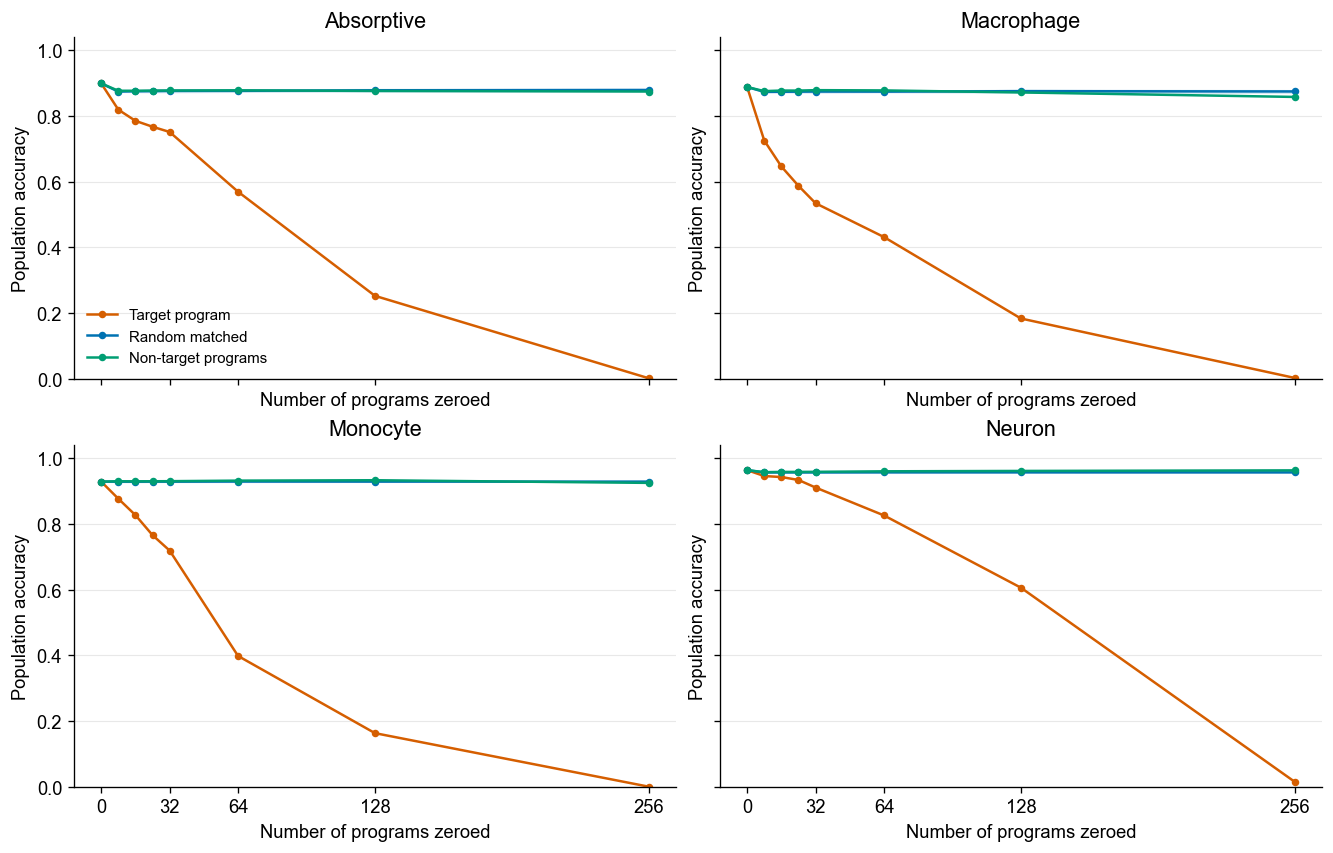

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True, layout="constrained")
for ax, population in zip(axes.flat, populations):
    for condition, color in colors.items():
        subset = curves.loc[curves.subtype.eq(population) & curves.condition.eq(condition)].sort_values("n_zeroed")
        x = np.r_[0, subset.n_zeroed.to_numpy()]
        y = np.r_[subset.base_accuracy.iloc[0], subset.accuracy.to_numpy()]
        ax.plot(x, y, marker="o", markersize=3.5, color=color, label=condition)
        if condition == "Random matched":
            sd = np.r_[0, subset.accuracy_sd.fillna(0).to_numpy()]
            ax.fill_between(x, np.maximum(0, y-sd), np.minimum(1, y+sd), color=color, alpha=0.15)
    ax.set_title(pretty(population))
    ax.set_ylim(0, 1.04)
    ax.set_xticks([0, 32, 64, 128, 256])
    ax.grid(axis="y", color="#e8e8e8", linewidth=0.7)
    ax.set_xlabel("Number of programs zeroed")
    ax.set_ylabel("Population accuracy")
axes[0, 0].legend(fontsize=9)
save_figure(fig, OUTPUT, "pangi_program_ablation_dose_response")
plt.show()

## 3. Compare retained accuracy

Retained accuracy is 100 times the post-ablation accuracy divided by the original accuracy. The example below removes 128 programs in each condition. Ratios above 100% indicate a small improvement after ablation.

condition,Target program,Random matched,Non-target programs
subtype,,,
Absorptive,28.0,97.7,97.4
Macrophage,20.6,98.6,98.1
Monocyte,17.5,100.0,100.5
Neuron,62.9,99.3,99.7


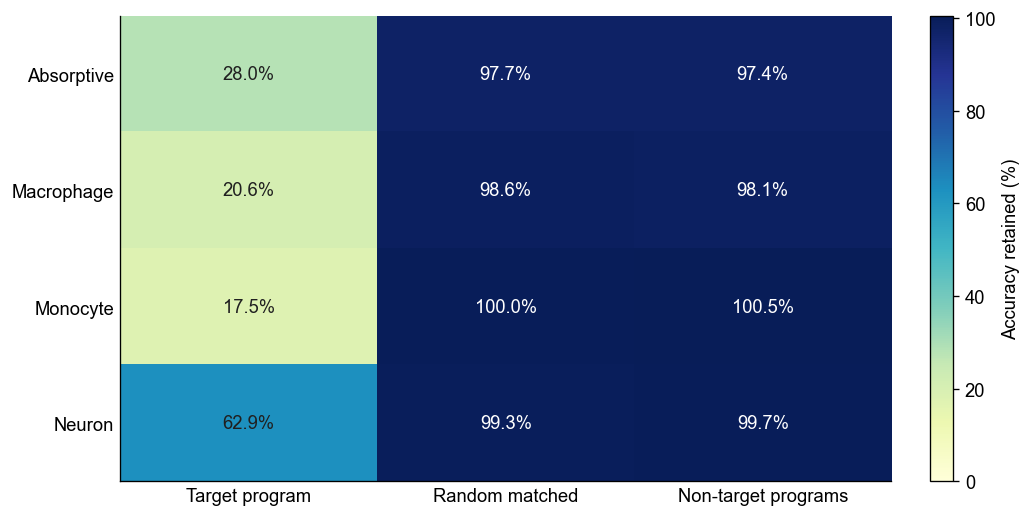

In [4]:
N_ZEROED = 128
selected = curves.loc[curves.n_zeroed.eq(N_ZEROED) & curves.subtype.isin(populations)].copy()
selected["retained_accuracy_percent"] = 100 * selected.accuracy / selected.base_accuracy
retained = selected.pivot(index="subtype", columns="condition", values="retained_accuracy_percent").loc[populations, conditions]
display(retained.round(1))

fig, ax = plt.subplots(figsize=(8.5, 4.2), layout="constrained")
image = ax.imshow(retained, cmap="YlGnBu", vmin=0, vmax=max(100, retained.to_numpy().max()), aspect="auto")
ax.set_xticks(range(3), conditions)
ax.set_yticks(range(4), [pretty(p) for p in populations])
ax.tick_params(length=0)
for row in range(4):
    for col in range(3):
        value = retained.iloc[row, col]
        ax.text(col, row, f"{value:.1f}%", ha="center", va="center",
                color="white" if value > 65 else "#202020")
fig.colorbar(image, ax=ax, label="Accuracy retained (%)")
save_figure(fig, OUTPUT, "pangi_program_ablation_retained_accuracy")
plt.show()

## 4. Inspect target-class probabilities

These distributions show the probability assigned to the annotated population before and after removal of 128 programs. Random and non-target values are per-cell averages across control sets.

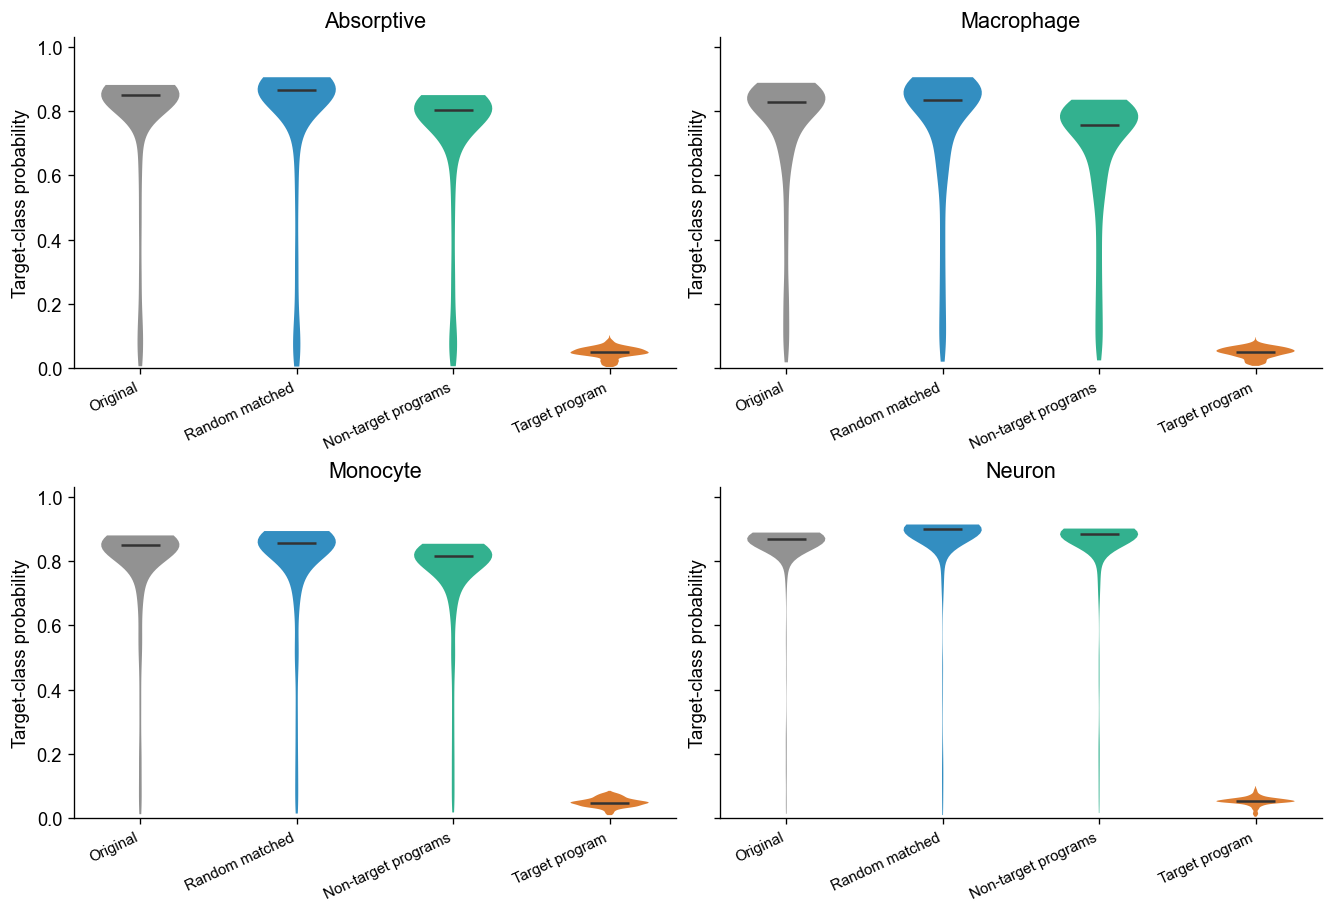

In [5]:
order = ["Original", "Random matched", "Non-target programs", "Target program"]
condition_colors = ["#777777", "#0072B2", "#009E73", "#D55E00"]
assert set(order) <= set(probabilities.condition)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True, layout="constrained")
for ax, population in zip(axes.flat, populations):
    values = [probabilities.loc[probabilities.cell_type.eq(population) & probabilities.condition.eq(c),
                                 "target_probability"].to_numpy() for c in order]
    violin = ax.violinplot(values, positions=range(4), showextrema=False, showmedians=True)
    for body, color in zip(violin["bodies"], condition_colors):
        body.set_facecolor(color)
        body.set_alpha(0.8)
    violin["cmedians"].set_color("#333333")
    ax.set_xticks(range(4), order, rotation=25, ha="right", fontsize=9)
    ax.set_ylim(0, 1.03)
    ax.set_title(pretty(population))
    ax.set_ylabel("Target-class probability")
save_figure(fig, OUTPUT, "pangi_program_ablation_probabilities")
plt.show()

Removing target-associated programs reduces retained accuracy and target-class probability more strongly than the matched controls. This establishes prediction relevance within the fitted model; it is not evidence of a causal biological intervention.